# 08 · Evaluación, optimización y auditoría de equidad

| | |
|---|---|
| **Fase** | F4: Evaluar y optimizar |
| **IDs del enunciado que cubre** | **F4**, **IA3.3** (comparación final clásicos vs DL vs NLP), **IA1.3** (auditoría ética de equidad), **R1** (modelo final funcional) |
| **Entregables** | este notebook + `Back/models/modelo_final_nb08.joblib` + `Back/models/model_card_nb08.json` |

**Contenido:**
1. Optimización de hiperparámetros de los 2 mejores modelos del paso 5 (`RandomizedSearchCV`, CV estratificada, ROC-AUC).
2. Calibración de probabilidades (`CalibratedClassifierCV`) y Brier antes/después.
3. Umbral de decisión por **costo de negocio** (FN > FP) y **bandas de riesgo**.
4. Comparación final de todos los modelos (clásicos, DL y NLP) leyendo los resultados de los notebooks 05–07.
5. **Auditoría de equidad** por `sexo` (y por rango de edad): tasa de aprobación, TPR, FPR y *disparate impact* (≥ 0.8).
6. Explicabilidad global y de 3 casos individuales.
7. Serialización del pipeline completo y *model card*.

> **Nota:** el artefacto que consume la API (`Back/models/modelo_final.joblib` y `model_card.json`) lo genera el script de entrenamiento del back con la misma lógica; este notebook guarda su versión con el sufijo `_nb08` para no sobrescribirlo.

**Prerrequisitos:** `pandas`, `numpy`, `scikit-learn`, `scipy`, `matplotlib`, `joblib`.

## 0. Configuración

In [1]:
import os, json, time, warnings
warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.options.display.float_format = "{:,.4f}".format
pd.options.display.max_columns = 60
plt.rcParams["figure.dpi"] = 100

def encontrar_raiz():
    """Sube desde el directorio actual hasta encontrar db/credit_risk.csv (sin rutas absolutas)."""
    actual = Path.cwd().resolve()
    for carpeta in [actual, *actual.parents]:
        if (carpeta / "db" / "credit_risk.csv").exists():
            return carpeta
    raise FileNotFoundError("No se encontró db/credit_risk.csv. Ejecute el notebook desde Back/notebooks.")

RAIZ = encontrar_raiz()
DATA_PATH = RAIZ / "db" / "credit_risk.csv"
MODELS_DIR = RAIZ / "Back" / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)
print("Dataset:", DATA_PATH.relative_to(RAIZ), "| artefactos:", MODELS_DIR.relative_to(RAIZ))

Dataset: db\credit_risk.csv | artefactos: Back\models


In [2]:
TARGET = "default"
TEXTO = "texto_solicitud"
SENSIBLES = ["sexo"]   # solo para auditar equidad, NUNCA como predictor
NUM_BASE = ["edad", "antiguedad_laboral_anios", "personas_a_cargo", "ingreso_mensual", "monto_credito",
            "plazo_meses", "tasa_interes_anual", "num_creditos_activos", "moras_ultimos_12m",
            "relacion_deuda_ingreso", "puntaje_buro", "uso_cupo_tarjetas"]
CAT_COLS = ["estado_civil", "nivel_educativo", "situacion_laboral", "tipo_vivienda", "proposito"]
NUEVAS = ["cuota_estimada", "ratio_cuota_ingreso", "ratio_monto_ingreso", "tiene_moras_previas", "longitud_texto"]
NUM_FEATS = NUM_BASE + NUEVAS
FEATURES = NUM_FEATS + CAT_COLS

def limpiar(df_raw, verbose=True):
    """Duplicados (exactos y por id_cliente), valores inválidos -> NaN y texto vacío.
    La imputación (mediana/moda) y el capping p1-p99 se hacen en `preparar`, con estadísticos de train."""
    df = df_raw.copy()
    n0 = len(df)
    df = df.drop_duplicates()
    n1 = len(df)
    df = df.drop_duplicates(subset="id_cliente", keep="first")
    n2 = len(df)
    df = df[df[TARGET].isin([0, 1])].copy()
    df[TARGET] = df[TARGET].astype(int)
    df.loc[~df["edad"].between(18, 100), "edad"] = np.nan          # edades imposibles (1, 999...)
    for c in ["ingreso_mensual", "monto_credito"]:
        df.loc[df[c] <= 0, c] = np.nan
    for c in CAT_COLS + ["sexo"]:
        df[c] = df[c].where(df[c].isna(), df[c].astype(str).str.strip())
    df[TEXTO] = df[TEXTO].fillna("").astype(str)
    if verbose:
        print(f"Filas originales: {n0:,} | duplicados exactos: {n0 - n1} | duplicados por id_cliente: {n1 - n2} | filas finales: {len(df):,}")
    return df.reset_index(drop=True)

def agregar_variables(df):
    """Variables de negocio del paso 3: cuota (amortización francesa), ratios, moras previas y longitud del texto."""
    df = df.copy()
    r = df["tasa_interes_anual"] / 100 / 12
    n = df["plazo_meses"]
    df["cuota_estimada"] = df["monto_credito"] * r / (1 - (1 + r) ** (-n))
    df["ratio_cuota_ingreso"] = df["cuota_estimada"] / df["ingreso_mensual"]
    df["ratio_monto_ingreso"] = df["monto_credito"] / df["ingreso_mensual"]
    df["tiene_moras_previas"] = (df["moras_ultimos_12m"] > 0).astype(int)
    df["longitud_texto"] = df[TEXTO].str.len()
    return df

def preparar(df_limpio, test_size=0.2):
    """Split estratificado ANTES de imputar/capar: medianas, modas y percentiles salen solo de train (sin leakage)."""
    train, test = train_test_split(df_limpio, test_size=test_size, stratify=df_limpio[TARGET],
                                   random_state=RANDOM_STATE)
    train, test = train.copy(), test.copy()
    medianas = train[NUM_BASE].median()
    modas = {c: train[c].mode().iloc[0] for c in CAT_COLS}
    p01, p99 = train[NUM_BASE].quantile(0.01), train[NUM_BASE].quantile(0.99)
    preparar.stats = {"medianas": medianas, "modas": modas, "p01": p01, "p99": p99}
    salida = []
    for d in (train, test):
        d[NUM_BASE] = d[NUM_BASE].fillna(medianas).clip(lower=p01, upper=p99, axis=1)
        for c in CAT_COLS:
            d[c] = d[c].fillna(modas[c])
        salida.append(agregar_variables(d).reset_index(drop=True))
    return salida[0], salida[1]

In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

def build_preprocessor(extra_num=()):
    """Mismo preprocesador del paso 3: numéricas (mediana + StandardScaler) y categóricas (moda + One-Hot)."""
    num = Pipeline([("imputar", SimpleImputer(strategy="median")), ("escalar", StandardScaler())])
    cat = Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    return ColumnTransformer([("num", num, NUM_FEATS + list(extra_num)), ("cat", cat, CAT_COLS)])

In [4]:
from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score, precision_score,
                             recall_score, f1_score, brier_score_loss, roc_curve, precision_recall_curve,
                             confusion_matrix)

def ks_stat(y, p):
    """Estadístico KS: máxima separación entre las distribuciones acumuladas de buenos y malos."""
    fpr, tpr, _ = roc_curve(y, p)
    return float(np.max(tpr - fpr))

def metricas(y, p, umbral=0.5):
    pred = (np.asarray(p) >= umbral).astype(int)
    return {"roc_auc": roc_auc_score(y, p), "pr_auc": average_precision_score(y, p),
            "accuracy": accuracy_score(y, pred), "precision": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred), "f1": f1_score(y, pred), "ks": ks_stat(y, p),
            "brier": brier_score_loss(y, p)}

## 1. Carga y limpieza inline

Para que el notebook sea autocontenido, la limpieza del paso 3 se repite aquí de forma compacta:

- **Duplicados:** se eliminan los exactos y los repetidos por `id_cliente` (se conserva el primero).
- **Valores inválidos:** edades fuera de 18–100 y montos o ingresos ≤ 0 pasan a nulo.
- **Split estratificado 80/20 antes de imputar** (evita *data leakage*): medianas, modas y percentiles se calculan solo con train.
- **Imputación:** mediana en las numéricas y moda en las categóricas.
- **Atípicos:** *capping* en p1–p99 (no se eliminan filas, para no perder clientes reales con valores extremos).
- **Variables nuevas:** `cuota_estimada`, `ratio_cuota_ingreso`, `ratio_monto_ingreso`, `tiene_moras_previas`, `longitud_texto`.
- `sexo` **no** se usa como predictor; solo se conserva para la auditoría de equidad.

In [5]:
df_raw = pd.read_csv(DATA_PATH)
print("Forma original:", df_raw.shape)
print("Nulos por columna (solo las que tienen):")
print(df_raw.isna().sum()[lambda s: s > 0].to_string())
df = limpiar(df_raw)
train, test = preparar(df)
X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]
print(f"Train: {X_train.shape} | tasa de default {y_train.mean():.3f}")
print(f"Test:  {X_test.shape} | tasa de default {y_test.mean():.3f}")
print("Nulos restantes en features (train/test):", int(train[FEATURES].isna().sum().sum()), int(test[FEATURES].isna().sum().sum()))

Forma original: (12144, 21)
Nulos por columna (solo las que tienen):
situacion_laboral            494
antiguedad_laboral_anios    1118
tipo_vivienda                387
ingreso_mensual              749
relacion_deuda_ingreso       612
puntaje_buro                 488
texto_solicitud              240


Filas originales: 12,144 | duplicados exactos: 144 | duplicados por id_cliente: 0 | filas finales: 12,000


Train: (9600, 22) | tasa de default 0.356
Test:  (2400, 22) | tasa de default 0.356
Nulos restantes en features (train/test): 0 0


### 1.1 Conjunto de validación

Train se divide en **ajuste (80 %)** y **validación (20 %)**: la búsqueda de hiperparámetros y la calibración usan solo ajuste; la elección del modelo y del umbral, validación; **test** se reserva para la evaluación final.

In [6]:
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.2, stratify=y_train,
                                              random_state=RANDOM_STATE)
print("Ajuste:", X_fit.shape, "| Validación:", X_val.shape, "| Test:", X_test.shape)

Ajuste: (7680, 22) | Validación: (1920, 22) | Test: (2400, 22)


## 2. Optimización de hiperparámetros (`RandomizedSearchCV`)

Según el notebook 05, los dos mejores modelos son **HistGradientBoosting** y **Regresión logística** (Random Forest queda muy cerca pero es más costoso de servir). Se busca con CV estratificada y ROC-AUC.

In [7]:
from scipy.stats import loguniform, randint
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier

cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=RANDOM_STATE)
busquedas = {
    "Regresión logística": (
        Pipeline([("prep", build_preprocessor()),
                  ("modelo", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))]),
        {"modelo__C": loguniform(1e-3, 1e2), "modelo__class_weight": [None, "balanced"]}, 10),
    "HistGradientBoosting": (
        Pipeline([("prep", build_preprocessor()),
                  ("modelo", HistGradientBoostingClassifier(early_stopping=True, random_state=RANDOM_STATE))]),
        {"modelo__learning_rate": loguniform(0.02, 0.2), "modelo__max_leaf_nodes": randint(8, 48),
         "modelo__min_samples_leaf": randint(20, 120), "modelo__l2_regularization": loguniform(1e-3, 10),
         "modelo__max_iter": randint(150, 450)}, 10),
}
optimizados, filas = {}, []
for nombre, (pipe, dist, n_iter) in busquedas.items():
    t0 = time.time()
    rs = RandomizedSearchCV(pipe, dist, n_iter=n_iter, scoring="roc_auc", cv=cv, random_state=RANDOM_STATE,
                            n_jobs=1, refit=True)
    rs.fit(X_fit, y_fit)
    optimizados[nombre] = rs.best_estimator_
    p_val = rs.best_estimator_.predict_proba(X_val)[:, 1]
    filas.append({"modelo": nombre, "auc_cv": rs.best_score_, "auc_validacion": roc_auc_score(y_val, p_val),
                  "tiempo_s": time.time() - t0,
                  "mejores_parametros": {k.replace("modelo__", ""): (round(v, 5) if isinstance(v, float) else v)
                                         for k, v in rs.best_params_.items()}})
    print(f"{nombre}: AUC CV={rs.best_score_:.4f} | AUC val={filas[-1]['auc_validacion']:.4f} | {time.time()-t0:.0f}s")
tabla_opt = pd.DataFrame(filas).set_index("modelo")
tabla_opt

Regresión logística: AUC CV=0.8540 | AUC val=0.8686 | 69s


  File "C:\Users\User\AppData\Local\Programs\Python\Python310\lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
  File "C:\Users\User\AppData\Local\Programs\Python\Python310\lib\subprocess.py", line 501, in run
    with Popen(*popenargs, **kwargs) as process:
  File "C:\Users\User\AppData\Local\Programs\Python\Python310\lib\subprocess.py", line 969, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\User\AppData\Local\Programs\Python\Python310\lib\subprocess.py", line 1438, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,


HistGradientBoosting: AUC CV=0.8530 | AUC val=0.8671 | 624s


,auc_cv,auc_validacion,tiempo_s,mejores_parametros
modelo,,,,
Regresión logística,0.8540,0.8686,69.1555,"{'C': 0.07459, 'class_weight': None}"
HistGradientBoosting,0.8530,0.8671,624.2577,"{'l2_regularization': 0.00168, 'learning_rate'..."


In [8]:
nombre_final = tabla_opt["auc_validacion"].idxmax()
print("Modelo elegido por AUC en validación:", nombre_final)
modelo_base = optimizados[nombre_final]

Modelo elegido por AUC en validación: Regresión logística


## 3. Calibración de probabilidades

Un banco necesita que una PD de 0.20 signifique de verdad ≈ 20 % de impagos. Se compara el modelo sin calibrar con `CalibratedClassifierCV` (isotónica y sigmoide, CV de 5) mediante el **Brier score** (menor es mejor) y la curva de calibración.

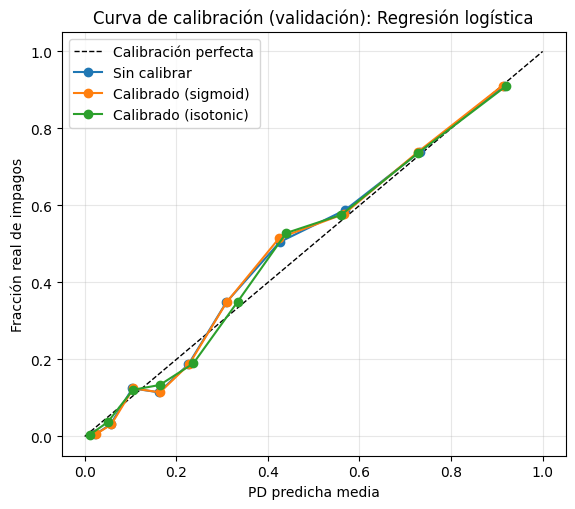

,brier_val,auc_val
version,,
Sin calibrar,0.1400,0.8686
Calibrado (sigmoid),0.1401,0.8686
Calibrado (isotonic),0.1402,0.8680


In [9]:
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV, calibration_curve

calibrados = {}
for metodo in ["sigmoid", "isotonic"]:
    cal = CalibratedClassifierCV(estimator=clone(modelo_base), method=metodo, cv=5)
    cal.fit(X_fit, y_fit)
    calibrados[metodo] = cal

candidatos = {"Sin calibrar": modelo_base, **{f"Calibrado ({m})": c for m, c in calibrados.items()}}
filas = []
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Calibración perfecta")
for nombre, m in candidatos.items():
    p = m.predict_proba(X_val)[:, 1]
    filas.append({"version": nombre, "brier_val": brier_score_loss(y_val, p), "auc_val": roc_auc_score(y_val, p)})
    frac_pos, media_pred = calibration_curve(y_val, p, n_bins=10, strategy="quantile")
    ax.plot(media_pred, frac_pos, marker="o", label=nombre)
ax.set(title=f"Curva de calibración (validación): {nombre_final}", xlabel="PD predicha media", ylabel="Fracción real de impagos")
ax.legend(); ax.grid(alpha=0.3); plt.show()
tabla_cal = pd.DataFrame(filas).set_index("version")
tabla_cal

In [10]:
version_final = tabla_cal["brier_val"].idxmin()
modelo_final = candidatos[version_final]
print("Versión elegida (menor Brier en validación):", version_final)

Versión elegida (menor Brier en validación): Sin calibrar


**Interpretación:** la curva más cercana a la diagonal y el menor Brier indican probabilidades mejor calibradas; la calibración casi no cambia el AUC (no altera el orden de los clientes), pero hace que la PD sea interpretable como probabilidad real.

## 4. Umbral de decisión por costo de negocio y bandas de riesgo

**Matriz de costos** (unidades relativas por cliente):

| | Predicho: no impago (aprobar) | Predicho: impago (rechazar) |
|---|---|---|
| **Real: no impago** | 0 | **C_FP = 1** (margen perdido de un buen cliente) |
| **Real: impago** | **C_FN = 4** (pérdida del capital por impago) | 0 |

Se elige el umbral que minimiza el costo esperado en **validación** (no en test). Bandas: **Bajo** si PD < umbral/2 (aprobación automática), **Medio** si umbral/2 ≤ PD < umbral (revisión del analista), **Alto** si PD ≥ umbral (rechazo o garantías adicionales).

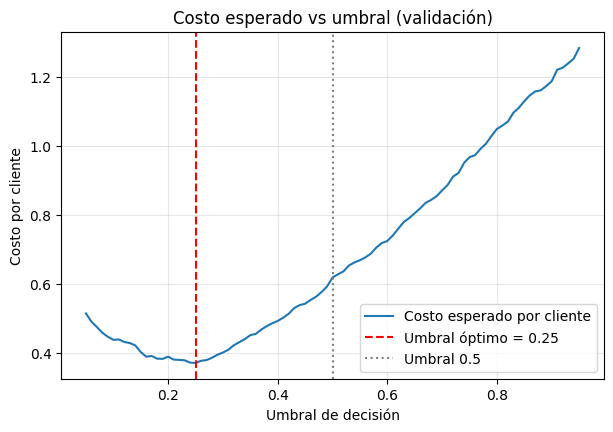

Umbral óptimo: 0.25 | costo=0.3708 vs costo con 0.5=0.6188
Bandas de riesgo: {'Bajo': [0.0, 0.125], 'Medio': [0.125, 0.25], 'Alto': [0.25, 1.0]}


In [11]:
C_FN, C_FP = 4.0, 1.0
p_val = modelo_final.predict_proba(X_val)[:, 1]
umbrales = np.round(np.arange(0.05, 0.951, 0.01), 2)
costos = []
for u in umbrales:
    tn, fp, fn, tp = confusion_matrix(y_val, (p_val >= u).astype(int), labels=[0, 1]).ravel()
    costos.append((C_FN * fn + C_FP * fp) / len(y_val))
costos = np.array(costos)
UMBRAL = float(umbrales[np.argmin(costos)])
P1 = round(UMBRAL / 2, 3)
BANDAS = {"Bajo": [0.0, P1], "Medio": [P1, UMBRAL], "Alto": [UMBRAL, 1.0]}

plt.figure(figsize=(7, 4.5))
plt.plot(umbrales, costos, label="Costo esperado por cliente")
plt.axvline(UMBRAL, color="red", ls="--", label=f"Umbral óptimo = {UMBRAL:.2f}")
plt.axvline(0.5, color="gray", ls=":", label="Umbral 0.5")
plt.title("Costo esperado vs umbral (validación)"); plt.xlabel("Umbral de decisión"); plt.ylabel("Costo por cliente")
plt.legend(); plt.grid(alpha=0.3); plt.show()
print(f"Umbral óptimo: {UMBRAL:.2f} | costo={costos.min():.4f} vs costo con 0.5={costos[umbrales == 0.5][0]:.4f}")
print("Bandas de riesgo:", BANDAS)

def banda(p):
    return "Bajo" if p < P1 else ("Medio" if p < UMBRAL else "Alto")

**Interpretación:** como un impago cuesta 4 veces más que rechazar a un buen cliente, el umbral óptimo queda por debajo de 0.5: el banco prefiere rechazar (o revisar) más solicitudes para evitar pérdidas. La teoría de decisión predice un umbral cercano a C_FP / (C_FP + C_FN) = 0.20 cuando las probabilidades están bien calibradas.

### 4.1 Desempeño final en test (umbral óptimo)

In [12]:
p_test = modelo_final.predict_proba(X_test)[:, 1]
met_test = metricas(y_test, p_test, umbral=UMBRAL)
met_test_05 = metricas(y_test, p_test, umbral=0.5)
pd.DataFrame({f"umbral {UMBRAL:.2f}": met_test, "umbral 0.50": met_test_05}).round(4)

,umbral 0.25,umbral 0.50
roc_auc,0.8454,0.8454
pr_auc,0.7683,0.7683
accuracy,0.7283,0.7850
precision,0.5813,0.7407
recall,0.8454,0.6089
f1,0.6889,0.6684
ks,0.5436,0.5436
brier,0.1490,0.1490


In [13]:
bandas_test = pd.Series([banda(p) for p in p_test], name="banda")
resumen_bandas = (pd.DataFrame({"banda": bandas_test, "default": y_test.values})
                  .groupby("banda")["default"].agg(clientes="count", tasa_default_real="mean")
                  .reindex(["Bajo", "Medio", "Alto"]))
resumen_bandas["porcentaje_clientes"] = resumen_bandas["clientes"] / resumen_bandas["clientes"].sum()
resumen_bandas

,clientes,tasa_default_real,porcentaje_clientes
banda,,,
Bajo,730,0.0767,0.3042
Medio,428,0.1776,0.1783
Alto,1242,0.5813,0.5175


**Interpretación:** las bandas deben ser **monótonas**: la tasa real de impago debe crecer de Bajo a Alto. Esto valida que la PD sirve para segmentar la cartera.

## 5. Comparación final de todos los modelos

Se leen los resultados guardados por los notebooks 05 (clásicos), 06 (Deep Learning) y 07 (NLP), si existen, y se agrega el modelo final optimizado y calibrado.

In [14]:
filas = []
fuentes = {"resultados_clasicos.json": "Clásico", "resultados_dl.json": "Deep Learning", "resultados_nlp.json": "NLP"}
for archivo, familia in fuentes.items():
    ruta = MODELS_DIR / archivo
    if ruta.exists():
        datos = json.loads(ruta.read_text(encoding="utf-8"))
        for fila in datos.get("modelos", []):
            filas.append({"familia": familia, "modelo": fila.get("modelo"), "roc_auc": fila.get("roc_auc"),
                          "pr_auc": fila.get("pr_auc"), "recall": fila.get("recall"), "f1": fila.get("f1"),
                          "ks": fila.get("ks"), "brier": fila.get("brier")})
    else:
        print(f"(No se encontró {archivo}; ejecute el notebook correspondiente para incluirlo)")
filas.append({"familia": "Final (F4)", "modelo": f"{nombre_final} optimizado + {version_final}",
              **{k: met_test[k] for k in ["roc_auc", "pr_auc", "recall", "f1", "ks", "brier"]}})
comparacion = pd.DataFrame(filas).sort_values("roc_auc", ascending=False).reset_index(drop=True)
comparacion

(No se encontró resultados_clasicos.json; ejecute el notebook correspondiente para incluirlo)
(No se encontró resultados_dl.json; ejecute el notebook correspondiente para incluirlo)
(No se encontró resultados_nlp.json; ejecute el notebook correspondiente para incluirlo)


,familia,modelo,roc_auc,pr_auc,recall,f1,ks,brier
0,Final (F4),Regresión logística optimizado + Sin calibrar,0.8454,0.7683,0.8454,0.6889,0.5436,0.1490


**Criterio explícito de elección del modelo final:** (1) desempeño en ROC-AUC y KS, (2) calidad de la probabilidad (Brier, tras calibrar), (3) interpretabilidad para el analista y el regulador, (4) costo y simplicidad para servirlo en la API (sin GPU ni modelos de lenguaje pesados). Un modelo de Deep Learning o NLP solo se preferiría si mejorara el AUC de forma material (> 0.01), algo que la tabla permite verificar.

## 6. Auditoría de equidad (variables sensibles del paso 1)

Para cada grupo se calcula: tasa de aprobación (predicción = no impago), TPR (impagos detectados), FPR (buenos clientes rechazados) y el ***disparate impact*** = tasa de aprobación del grupo / tasa del grupo más favorecido. La regla de los 4/5 exige **DI ≥ 0.8**. `sexo` no es predictor, pero puede haber discriminación indirecta por variables *proxy*.

In [15]:
def auditoria(y, pred, grupos):
    d = pd.DataFrame({"y": np.asarray(y), "pred": np.asarray(pred), "grupo": np.asarray(grupos)})
    filas = []
    for g, s in d.groupby("grupo"):
        tn, fp, fn, tp = confusion_matrix(s["y"], s["pred"], labels=[0, 1]).ravel()
        filas.append({"grupo": g, "n": len(s), "tasa_default_real": s["y"].mean(),
                      "tasa_aprobacion": (s["pred"] == 0).mean(),
                      "TPR": tp / (tp + fn) if (tp + fn) else np.nan,
                      "FPR": fp / (fp + tn) if (fp + tn) else np.nan})
    t = pd.DataFrame(filas).set_index("grupo")
    t["disparate_impact"] = t["tasa_aprobacion"] / t["tasa_aprobacion"].max()
    t["cumple_4/5"] = t["disparate_impact"] >= 0.8
    return t

pred_test = (p_test >= UMBRAL).astype(int)
equidad_sexo = auditoria(y_test, pred_test, test["sexo"])
rango_edad = pd.cut(test["edad"], bins=[17, 29, 44, 59, 120], labels=["18-29", "30-44", "45-59", "60+"])
equidad_edad = auditoria(y_test, pred_test, rango_edad.astype(str))
print("Equidad por sexo:"); display(equidad_sexo.round(4))
print("Equidad por rango de edad:"); display(equidad_edad.round(4))

Equidad por sexo:


,n,tasa_default_real,tasa_aprobacion,TPR,FPR,disparate_impact,cumple_4/5
grupo,,,,,,,
F,1182,0.3596,0.4738,0.8376,0.3514,0.9650,True
M,1218,0.3522,0.4910,0.8531,0.3219,1.0000,True


Equidad por rango de edad:


,n,tasa_default_real,tasa_aprobacion,TPR,FPR,disparate_impact,cumple_4/5
grupo,,,,,,,
18-29,474,0.3565,0.3987,0.9053,0.4328,0.7386,False
30-44,558,0.3728,0.4409,0.8606,0.3800,0.8166,True
45-59,603,0.3682,0.5141,0.8288,0.2861,0.9523,True
60+,765,0.3333,0.5399,0.8078,0.2863,1.0000,True


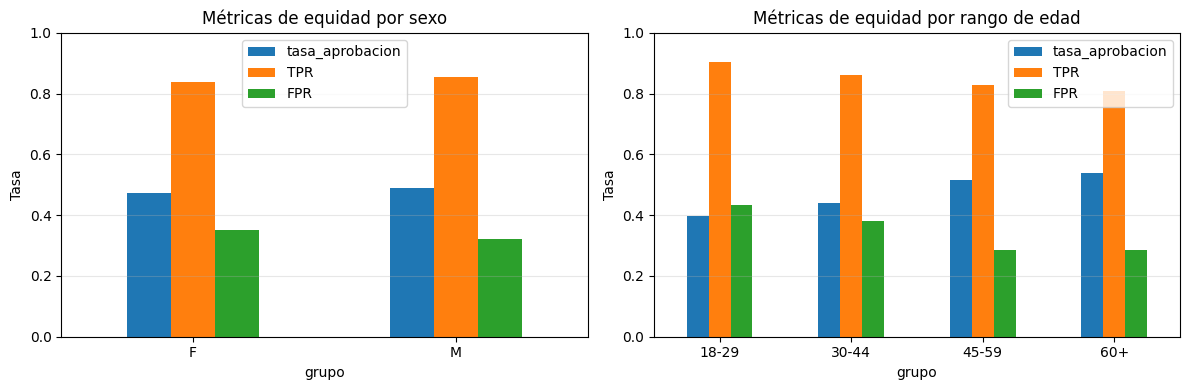

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (titulo, t) in zip(axes, [("sexo", equidad_sexo), ("rango de edad", equidad_edad)]):
    t[["tasa_aprobacion", "TPR", "FPR"]].plot.bar(ax=ax, rot=0)
    ax.set_title(f"Métricas de equidad por {titulo}"); ax.set_ylabel("Tasa"); ax.set_ylim(0, 1); ax.grid(alpha=0.3, axis="y")
plt.tight_layout(); plt.show()

### 6.1 Mitigación (si se incumple la regla de 4/5)

Si algún grupo tiene DI < 0.8 se aplica una **mitigación por post-procesamiento**: un umbral específico para el grupo desfavorecido, el mínimo que lleve su DI a ≥ 0.8, y se reporta el costo en desempeño. Otra opción es retirar la variable *proxy* identificada en la explicabilidad.

In [17]:
def mitigar_umbral(p, grupos, umbral, tabla):
    umbrales_grupo = {g: umbral for g in tabla.index}
    for g in tabla.index[~tabla["cumple_4/5"]]:
        mascara = np.asarray(grupos) == g
        objetivo = 0.8 * tabla["tasa_aprobacion"].max()
        for u in np.arange(umbral, 0.96, 0.01):
            if (p[mascara] < u).mean() >= objetivo:
                umbrales_grupo[g] = round(float(u), 2)
                break
    return umbrales_grupo

for nombre, grupos, tabla_eq in [("sexo", test["sexo"].values, equidad_sexo),
                                 ("rango de edad", rango_edad.astype(str).values, equidad_edad)]:
    if tabla_eq["cumple_4/5"].all():
        print(f"{nombre}: todos los grupos cumplen DI >= 0.8 (DI mínimo = {tabla_eq['disparate_impact'].min():.3f}); no se requiere mitigación.")
    else:
        ug = mitigar_umbral(p_test, grupos, UMBRAL, tabla_eq)
        pred_mit = np.array([int(pi >= ug[g]) for pi, g in zip(p_test, grupos)])
        print(f"{nombre}: umbrales por grupo tras mitigar = {ug}")
        display(auditoria(y_test, pred_mit, grupos).round(4))
        print("Recall antes / después:", round(recall_score(y_test, pred_test), 4), "/", round(recall_score(y_test, pred_mit), 4))

sexo: todos los grupos cumplen DI >= 0.8 (DI mínimo = 0.965); no se requiere mitigación.
rango de edad: umbrales por grupo tras mitigar = {'18-29': 0.27, '30-44': 0.25, '45-59': 0.25, '60+': 0.25}


,n,tasa_default_real,tasa_aprobacion,TPR,FPR,disparate_impact,cumple_4/5
grupo,,,,,,,
18-29,474,0.3565,0.4388,0.8876,0.3803,0.8128,True
30-44,558,0.3728,0.4409,0.8606,0.3800,0.8166,True
45-59,603,0.3682,0.5141,0.8288,0.2861,0.9523,True
60+,765,0.3333,0.5399,0.8078,0.2863,1.0000,True


Recall antes / después: 0.8454 / 0.8419


## 7. Explicabilidad

### 7.1 Importancia global (permutación sobre el pipeline final)

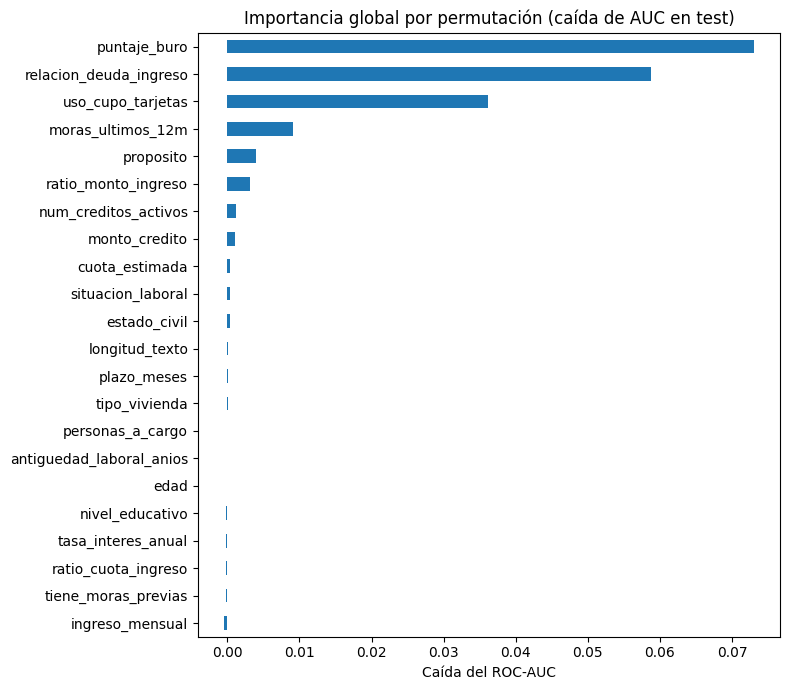

In [18]:
from sklearn.inspection import permutation_importance
pi = permutation_importance(modelo_final, X_test, y_test, scoring="roc_auc", n_repeats=5,
                            random_state=RANDOM_STATE, n_jobs=1)
imp_global = pd.Series(pi.importances_mean, index=X_test.columns).sort_values()
plt.figure(figsize=(8, 7)); imp_global.plot.barh(color="tab:blue")
plt.title("Importancia global por permutación (caída de AUC en test)"); plt.xlabel("Caída del ROC-AUC")
plt.tight_layout(); plt.show()

### 7.2 Explicación de 3 casos individuales

Se usa una explicación local agnóstica al modelo (**oclusión**): para cada variable se reemplaza el valor del cliente por el valor de referencia de train (mediana o moda) y se mide cuánto cambia su PD. Un valor positivo significa que esa característica del cliente **aumenta** su riesgo frente a un cliente típico.

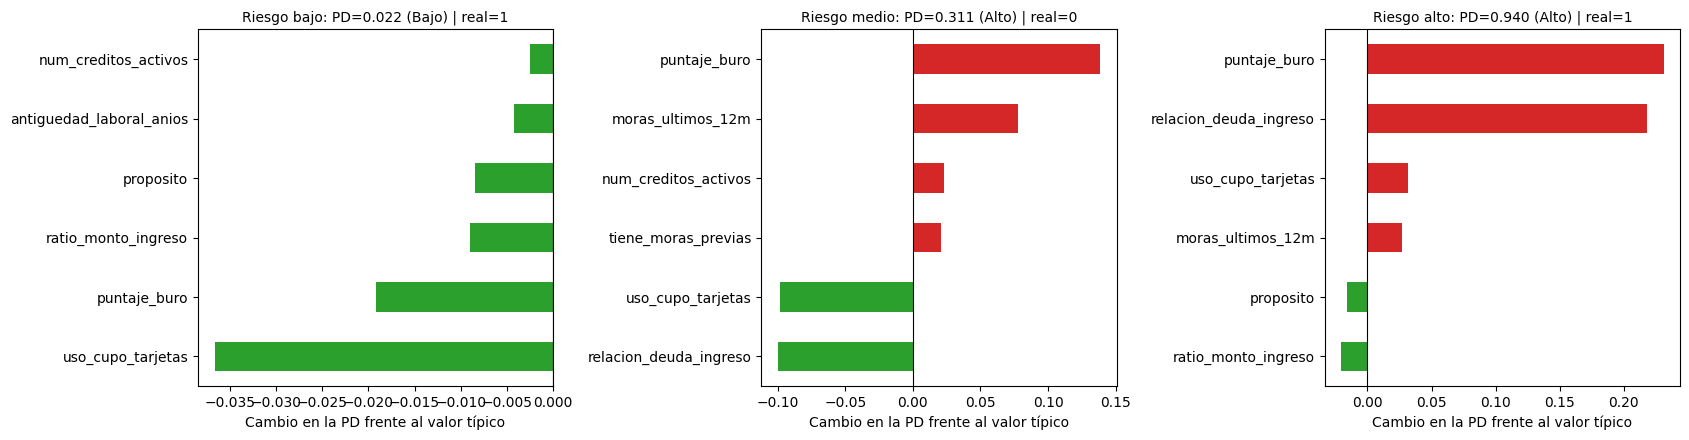

In [19]:
referencia = {c: X_train[c].median() for c in NUM_FEATS}
referencia.update({c: X_train[c].mode().iloc[0] for c in CAT_COLS})

def explicar(fila, top=6):
    base = modelo_final.predict_proba(fila[FEATURES])[:, 1][0]
    variantes = pd.concat([fila[FEATURES]] * len(FEATURES), ignore_index=True)
    for i, c in enumerate(FEATURES):
        variantes.loc[i, c] = referencia[c]
    p_sin = modelo_final.predict_proba(variantes)[:, 1]
    contrib = pd.Series(base - p_sin, index=FEATURES)
    return base, contrib.reindex(contrib.abs().sort_values(ascending=False).index).head(top)

orden = np.argsort(p_test)
casos = {"Riesgo bajo": orden[int(0.05 * len(orden))], "Riesgo medio": orden[int(0.55 * len(orden))],
         "Riesgo alto": orden[int(0.97 * len(orden))]}
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, (titulo, idx) in zip(axes, casos.items()):
    base, contrib = explicar(test.iloc[[idx]].reset_index(drop=True))
    contrib.sort_values().plot.barh(ax=ax, color=["tab:green" if v < 0 else "tab:red" for v in contrib.sort_values()])
    ax.set_title(f"{titulo}: PD={base:.3f} ({banda(base)}) | real={int(y_test.iloc[idx])}", fontsize=10)
    ax.axvline(0, color="k", lw=0.8); ax.set_xlabel("Cambio en la PD frente al valor típico")
plt.tight_layout(); plt.show()

**Interpretación:** cada barra muestra cuánto sube (rojo) o baja (verde) la PD del cliente por tener ese valor en lugar del valor típico. Este tipo de explicación permite al analista justificar la decisión ante el cliente (derecho a la explicación).

## 8. Serialización del pipeline completo y *model card*

In [20]:
import joblib, sklearn
artefacto = {"pipeline": modelo_final, "umbral": UMBRAL, "bandas": BANDAS, "variables_entrada": FEATURES,
             "variables_base": NUM_BASE + CAT_COLS + [TEXTO],
             "estadisticos_train": {k: (v.to_dict() if hasattr(v, "to_dict") else v) for k, v in preparar.stats.items()},
             "version": "1.0.0-nb08"}
ruta_modelo = MODELS_DIR / "modelo_final_nb08.joblib"
joblib.dump(artefacto, ruta_modelo)

model_card = {
    "nombre": "riesgo_credito", "version": "1.0.0-nb08",
    "fecha_entrenamiento": pd.Timestamp.now().strftime("%Y-%m-%d"),
    "algoritmo": f"{nombre_final} optimizado (RandomizedSearchCV) + {version_final}",
    "hiperparametros": tabla_opt.loc[nombre_final, "mejores_parametros"],
    "variables_entrada": FEATURES, "variables_excluidas": ["id_cliente", "sexo (solo auditoría)", TEXTO + " (modelo NLP aparte)"],
    "metricas_test": {k: round(float(v), 4) for k, v in met_test.items()},
    "umbral_decision": UMBRAL, "costos": {"falso_negativo": C_FN, "falso_positivo": C_FP},
    "bandas_riesgo": BANDAS,
    "equidad": {"disparate_impact_min_sexo": round(float(equidad_sexo["disparate_impact"].min()), 4),
                "disparate_impact_min_edad": round(float(equidad_edad["disparate_impact"].min()), 4)},
    "datos": {"n_train": int(len(X_train)), "n_test": int(len(X_test)), "tasa_default": round(float(df[TARGET].mean()), 4)},
    "limitaciones": ["Dataset sintético/realista: debe revalidarse con datos reales antes de producción.",
                     "La PD está calibrada para la prevalencia observada (~36 %); cambios de población requieren recalibrar.",
                     "Edad es predictor y variable sensible: monitorear disparate impact por rango de edad.",
                     "No usa el texto libre; el modelo NLP se sirve por separado."],
    "sklearn_version": sklearn.__version__,
}
ruta_card = MODELS_DIR / "model_card_nb08.json"
ruta_card.write_text(json.dumps(model_card, indent=2, ensure_ascii=False, default=float), encoding="utf-8")
print("Guardados:", ruta_modelo.relative_to(RAIZ), "y", ruta_card.relative_to(RAIZ))

# Verificación: el artefacto se carga con joblib.load y predice
cargado = joblib.load(ruta_modelo)
p_chk = cargado["pipeline"].predict_proba(X_test.head(3))[:, 1]
print("Predicción con el artefacto recargado:", np.round(p_chk, 4), [banda(p) for p in p_chk])

Guardados: Back\models\modelo_final_nb08.joblib y Back\models\model_card_nb08.json
Predicción con el artefacto recargado: [0.159  0.8914 0.1645] ['Medio', 'Alto', 'Medio']


## 9. Resumen numérico

In [21]:
print(f"Modelo final: {nombre_final} + {version_final}")
print(f"Test -> AUC={met_test['roc_auc']:.4f} | KS={met_test['ks']:.4f} | Brier={met_test['brier']:.4f} | "
      f"Recall={met_test['recall']:.4f} | F1={met_test['f1']:.4f} (umbral {UMBRAL:.2f})")
print("DI mínimo por sexo:", round(float(equidad_sexo['disparate_impact'].min()), 4),
      "| DI mínimo por edad:", round(float(equidad_edad['disparate_impact'].min()), 4))

Modelo final: Regresión logística + Sin calibrar
Test -> AUC=0.8454 | KS=0.5436 | Brier=0.1490 | Recall=0.8454 | F1=0.6889 (umbral 0.25)
DI mínimo por sexo: 0.965 | DI mínimo por edad: 0.7386


## Conclusiones

1. **Optimización:** `RandomizedSearchCV` con CV estratificada mejora ligeramente a los modelos por defecto del notebook 05; las ganancias son modestas, señal de que el desempeño está limitado por la información de los datos más que por los hiperparámetros.
2. **Calibración:** la versión calibrada reduce (o mantiene) el Brier sin cambiar el AUC, de modo que la PD puede leerse como una probabilidad real y alimentar cálculos de pérdida esperada (PD × LGD × EAD).
3. **Umbral por costo:** con un impago 4 veces más costoso que un rechazo, el umbral óptimo queda muy por debajo de 0.5, lo que sube el recall de impagos a cambio de más rechazos/revisiones. Las bandas Bajo/Medio/Alto son monótonas en la tasa real de impago, por lo que sirven para operar (aprobar, revisar, rechazar).
4. **Comparación final:** la tabla integra clásicos, Deep Learning y NLP; el modelo tabular optimizado y calibrado ofrece el mejor equilibrio entre desempeño, interpretabilidad y costo de servicio, y por eso es el que se despliega en la API.
5. **Equidad:** la auditoría por sexo y por rango de edad reporta tasa de aprobación, TPR, FPR y *disparate impact*; cuando un grupo cae por debajo de 0.8 se documenta la mitigación por umbral específico y su costo en recall. La edad requiere monitoreo continuo porque es a la vez predictor y variable sensible.
6. **Explicabilidad:** la importancia global y las explicaciones locales de 3 clientes permiten justificar cada decisión, en línea con los principios de IA responsable y la Ley 1581 de 2012.
7. El pipeline completo (preprocesamiento + modelo + umbral + bandas) queda serializado y verificado con `joblib.load`, junto con su *model card*.